# Session 5 - Q1. Spatial-Domain Smoothing

Write a Python program to add noise to a grayscale image and perform spatial-domain smoothing using:
1. Image averaging
2. Mean filter
3. Gaussian filter
4. Low-pass filter

Experiment with different kernel sizes and compare the results.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
image_path = "input.jpg"
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if image is None:
    raise FileNotFoundError("Image could not be loaded.")

In [3]:
# Add Gaussian noise
noise = np.random.normal(0, 25, image.shape)
noisy_image = np.clip(image.astype(np.float32) + noise, 0, 255).astype(np.uint8)

In [4]:
# Image averaging using multiple noisy images
noisy_images = []

for i in range(5):
    noise = np.random.normal(0, 25, image.shape)
    noisy = np.clip(image.astype(np.float32) + noise, 0, 255).astype(np.uint8)
    noisy_images.append(noisy)

averaged_image = np.mean(noisy_images, axis=0).astype(np.uint8)

In [5]:
# Mean filter
mean_3 = cv2.blur(noisy_image, (3, 3))
mean_5 = cv2.blur(noisy_image, (5, 5))
mean_7 = cv2.blur(noisy_image, (7, 7))

# Gaussian filter
gaussian_3 = cv2.GaussianBlur(noisy_image, (3, 3), 0)
gaussian_5 = cv2.GaussianBlur(noisy_image, (5, 5), 0)
gaussian_7 = cv2.GaussianBlur(noisy_image, (7, 7), 0)

# Low-pass filter
low_pass_kernel = np.ones((5, 5), np.float32) / 25
low_pass_image = cv2.filter2D(noisy_image, -1, low_pass_kernel)

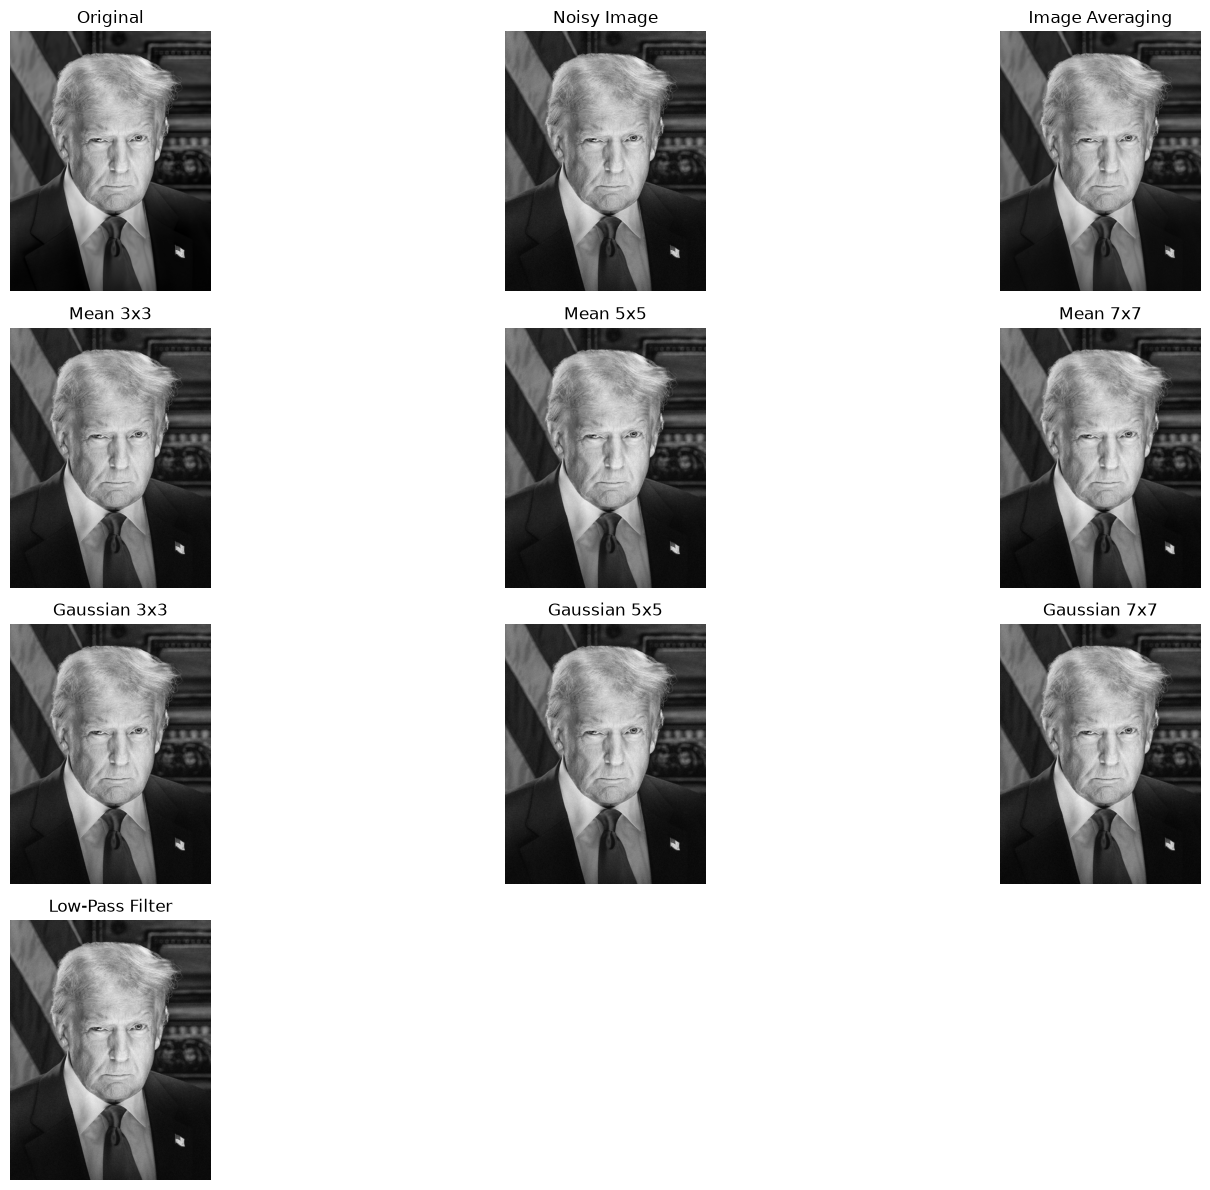

In [6]:
images = [
    image, noisy_image, averaged_image, mean_3, mean_5, mean_7,
    gaussian_3, gaussian_5, gaussian_7, low_pass_image
]
titles = [
    "Original", "Noisy Image", "Image Averaging", "Mean 3x3",
    "Mean 5x5", "Mean 7x7", "Gaussian 3x3", "Gaussian 5x5",
    "Gaussian 7x7", "Low-Pass Filter"
]

plt.figure(figsize=(15, 12))

for i in range(len(images)):
    plt.subplot(4, 3, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()